# Week 1 · Food Delivery Data Analysis: Dataset Understanding & Cleaning
**Kagnus Data Analytics Internship**

**Role:** Junior data analyst supporting a food-delivery operations team.

**Goal of this notebook:** understand the dataset, find its data-quality problems, clean it with every decision justified and logged, and export a reliable cleaned file for the later project weeks.

**How this notebook is organised**
1. Setup
2. Load and understand the dataset
3. Data-quality checks (nothing is changed in this section)
4. Cleaning, with a decision and a reason for each issue
5. Verification and export

**Ground rules followed:** the raw data is never modified, cleaning happens on a separate copy, nothing is deleted without investigation, no values are invented, and every number in the written explanations is calculated by code from the actual data.

## 1. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

def md_table(frame):
    # Turn a DataFrame into a Markdown table so results render cleanly on GitHub
    cols = [str(c) for c in frame.columns]
    lines = ["| " + " | ".join(cols) + " |", "| " + " | ".join(["---"] * len(cols)) + " |"]
    for _, row in frame.iterrows():
        lines.append("| " + " | ".join(str(v) for v in row.values) + " |")
    return "\n".join(lines)

def show_md(*lines):
    display(Markdown("\n".join(lines)))

## 2. Load and Understand the Dataset

**What:** load the raw CSV into a DataFrame called `df` and keep an untouched snapshot.
**Why:** all later checks must run against the original data, and the raw file must stay unchanged.
**Expect to learn:** how many records and columns there are, and whether the file loads without problems.

In [2]:
# Work out where the project folder is, so the notebook runs from the repo or from any single folder
CWD = os.getcwd()
PROJECT_ROOT = os.path.dirname(CWD) if os.path.basename(CWD).lower() == "notebooks" else CWD

RAW_FILENAME = "Food delivery Dataset.csv"      # change this if your downloaded file has a different name
candidates = [
    os.path.join(PROJECT_ROOT, "data", "raw", RAW_FILENAME),
    os.path.join(CWD, RAW_FILENAME),
    os.path.join(PROJECT_ROOT, RAW_FILENAME),
]
RAW_PATH = next((p for p in candidates if os.path.exists(p)), None)
if RAW_PATH is None:
    raise FileNotFoundError("Could not find the raw CSV. Looked in:\n  " + "\n  ".join(candidates))

df = pd.read_csv(RAW_PATH)                       # the raw data: never modified below
df_snapshot = df.copy()                          # used at the end to prove the raw data stayed unchanged

print("Loaded:", RAW_PATH)
print("Shape (rows, columns):", df.shape)

Loaded: C:\Users\HP\Documents\food-delivery-data-analysis\data\raw\Food delivery Dataset.csv
Shape (rows, columns): (45584, 20)


### 2.1 First inspection

In [3]:
print("HEAD"); display(df.head())
print("TAIL"); display(df.tail())
print("Shape:", df.shape)
print("Columns:", list(df.columns))
print()
df.info()

HEAD


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,12-02-2022,21:55,22:10,Fog,Jam,2,Snack,motorcycle,3.0,No,Metropolitian,46
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,13-02-2022,14:55,15:05,Stormy,High,1,Meal,motorcycle,1.0,No,Metropolitian,23
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,04-03-2022,17:30,17:40,Sandstorms,Medium,1,Drinks,scooter,1.0,No,Metropolitian,21
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,13-02-2022,09:20,09:30,Sandstorms,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,14-02-2022,19:50,20:05,Fog,Jam,1,Snack,scooter,1.0,No,Metropolitian,41


TAIL


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
45579,0x7c09,JAPRES04DEL01,30.0,4.8,26.902328,75.794257,26.912328,75.804257,24-03-2022,11:35,11:45,Windy,High,1,Meal,motorcycle,0.0,No,Metropolitian,32
45580,0xd641,AGRRES16DEL01,21.0,4.6,0.000000,0.000000,0.070000,0.070000,16-02-2022,19:55,20:10,Windy,Jam,0,Buffet,motorcycle,1.0,No,Metropolitian,36
45581,0x4f8d,CHENRES08DEL03,30.0,4.9,13.022394,80.242439,13.052394,80.272439,11-03-2022,23:50,24:05:00,Cloudy,Low,1,Drinks,scooter,0.0,No,Metropolitian,16
45582,0x5eee,COIMBRES11DEL01,20.0,4.7,11.001753,76.986241,11.041753,77.026241,07-03-2022,13:35,13:40,Cloudy,High,0,Snack,motorcycle,1.0,No,Metropolitian,26
45583,0x5fb2,RANCHIRES09DEL02,23.0,4.9,23.351058,85.325731,23.431058,85.405731,02-03-2022,17:10,17:15,Fog,Medium,2,Snack,scooter,1.0,No,Metropolitian,36


Shape: (45584, 20)
Columns: ['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weather_conditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Time_taken (min)']

<class 'pandas.DataFrame'>
RangeIndex: 45584 entries, 0 to 45583
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45584 non-null  str    
 1   Delivery_person_ID           45584 non-null  str    
 2   Delivery_person_Age          43730 non-null  float64
 3   Delivery_person_Ratings      43676 non-null  float64
 4   Restaurant_latitude          45584 non-null  float64
 5   Restaurant_longitude         45584 non-null  float64
 6   D

In [4]:
display(df.describe().round(2))

,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Vehicle_condition,multiple_deliveries,Time_taken (min)
count,43730.00,43676.00,45584.00,45584.00,45584.00,45584.00,45584.00,44591.00,45584.00
mean,29.57,4.63,17.02,70.23,17.47,70.84,1.02,0.74,26.29
std,5.82,0.33,8.19,22.89,7.34,21.12,0.84,0.57,9.38
min,15.00,1.00,-30.91,-88.37,0.01,0.01,0.00,0.00,10.00
25%,25.00,4.50,12.93,73.17,12.99,73.28,0.00,0.00,19.00
50%,30.00,4.70,18.55,75.90,18.63,76.00,1.00,1.00,26.00
75%,35.00,4.90,22.73,78.04,22.79,78.11,2.00,1.00,32.00
max,50.00,6.00,30.91,88.43,31.05,88.56,3.00,3.00,54.00


### 2.2 Column overview

The dataset came without a data dictionary, so the meanings below are **inferred from the column names** and are marked as assumptions. Data types and counts are calculated from the data.

In [5]:
MEANINGS = {
    "ID": "Order identifier (assumed unique per order; verified below)",
    "Delivery_person_ID": "Identifier of the delivery partner",
    "Delivery_person_Age": "Age of the delivery partner, in years",
    "Delivery_person_Ratings": "Rating of the delivery partner (scale not documented; checked below)",
    "Restaurant_latitude": "Latitude of the restaurant, in degrees",
    "Restaurant_longitude": "Longitude of the restaurant, in degrees",
    "Delivery_location_latitude": "Latitude of the delivery destination, in degrees",
    "Delivery_location_longitude": "Longitude of the delivery destination, in degrees",
    "Order_Date": "Date the order was placed (day-month-year assumed; verified below)",
    "Time_Orderd": "Time of day the order was placed (HH:MM)",
    "Time_Order_picked": "Time of day the order was picked up (HH:MM)",
    "Weather_conditions": "Weather during the delivery",
    "Road_traffic_density": "Traffic level during the delivery",
    "Vehicle_condition": "Condition of the delivery vehicle (coded integer; scale not documented)",
    "Type_of_order": "Category of food ordered",
    "Type_of_vehicle": "Vehicle used for the delivery",
    "multiple_deliveries": "Number of other deliveries carried at the same time (inferred from the name)",
    "Festival": "Whether the order was placed during a festival (Yes/No)",
    "City": "Type of city or area",
    "Time_taken (min)": "Delivery duration in minutes (the outcome to be explained in later weeks)",
}

overview = pd.DataFrame({
    "Column": df.columns,
    "Data type": [str(t) for t in df.dtypes],
    "Non-null": df.notna().sum().values,
    "Unique values": df.nunique().values,
    "Assumed meaning": [MEANINGS.get(c, "(not documented)") for c in df.columns],
})
show_md("**Column overview**", "", md_table(overview))

**Column overview**

| Column | Data type | Non-null | Unique values | Assumed meaning |
| --- | --- | --- | --- | --- |
| ID | str | 45584 | 45584 | Order identifier (assumed unique per order; verified below) |
| Delivery_person_ID | str | 45584 | 1320 | Identifier of the delivery partner |
| Delivery_person_Age | float64 | 43730 | 22 | Age of the delivery partner, in years |
| Delivery_person_Ratings | float64 | 43676 | 28 | Rating of the delivery partner (scale not documented; checked below) |
| Restaurant_latitude | float64 | 45584 | 657 | Latitude of the restaurant, in degrees |
| Restaurant_longitude | float64 | 45584 | 518 | Longitude of the restaurant, in degrees |
| Delivery_location_latitude | float64 | 45584 | 4373 | Latitude of the delivery destination, in degrees |
| Delivery_location_longitude | float64 | 45584 | 4373 | Longitude of the delivery destination, in degrees |
| Order_Date | str | 45584 | 44 | Date the order was placed (day-month-year assumed; verified below) |
| Time_Orderd | str | 43853 | 176 | Time of day the order was placed (HH:MM) |
| Time_Order_picked | str | 45584 | 193 | Time of day the order was picked up (HH:MM) |
| Weather_conditions | str | 44968 | 6 | Weather during the delivery |
| Road_traffic_density | str | 44983 | 4 | Traffic level during the delivery |
| Vehicle_condition | int64 | 45584 | 4 | Condition of the delivery vehicle (coded integer; scale not documented) |
| Type_of_order | str | 45584 | 4 | Category of food ordered |
| Type_of_vehicle | str | 45584 | 4 | Vehicle used for the delivery |
| multiple_deliveries | float64 | 44591 | 4 | Number of other deliveries carried at the same time (inferred from the name) |
| Festival | str | 45356 | 2 | Whether the order was placed during a festival (Yes/No) |
| City | str | 44384 | 3 | Type of city or area |
| Time_taken (min) | int64 | 45584 | 45 | Delivery duration in minutes (the outcome to be explained in later weeks) |

### 2.3 What does one row represent?

**What:** test whether `ID` identifies one order, and see how the delivery-partner ID repeats.
**Why:** the unit of analysis decides how every later count and average should be read.

In [6]:
n_rows = len(df)
n_ids = df["ID"].nunique()
n_partners = df["Delivery_person_ID"].nunique()

lines = [
    f"- The dataset has **{n_rows:,} rows** and **{n_ids:,} unique `ID` values**.",
    f"- It contains **{n_partners:,} unique delivery-partner IDs**, so a partner appears in about **{n_rows / n_partners:.1f} rows** on average.",
]
if n_ids == n_rows:
    lines.append("- Every `ID` is unique, so **each row represents one delivery order** (with its partner, location, time, conditions and duration).")
else:
    lines.append(f"- `ID` repeats for {n_rows - n_ids:,} rows, so not every row is a distinct order. The duplicates check in Section 3.2 investigates this.")
show_md(*lines)

- The dataset has **45,584 rows** and **45,584 unique `ID` values**.
- It contains **1,320 unique delivery-partner IDs**, so a partner appears in about **34.5 rows** on average.
- Every `ID` is unique, so **each row represents one delivery order** (with its partner, location, time, conditions and duration).

## 3. Data-Quality Checks

Nothing is changed in this section. Each check only measures a problem. Decisions are made in Section 4.

### 3.1 Missing values

**What:** count missing values per column, including text placeholders such as `"NaN "` that pandas does not recognise as missing.
**Why:** missing values bias averages and break calculations, and hidden placeholders would otherwise go unnoticed.
**Expect to learn:** which columns are affected and how serious the gaps are.

In [7]:
text_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
PLACEHOLDERS = {"nan", "null", "n/a", "na", ""}

def placeholder_mask(s):
    # True for text cells that are really placeholders for "missing" (e.g. 'NaN ')
    cleaned = s.astype("string").str.strip().str.lower()
    return s.notna() & cleaned.isin(PLACEHOLDERS)

real_missing = df.isna().sum()
hidden = pd.Series({c: int(placeholder_mask(df[c]).sum()) for c in text_cols}).reindex(df.columns).fillna(0).astype(int)
effective = real_missing + hidden

missing_table = pd.DataFrame({
    "Column": df.columns,
    "Missing (blank)": real_missing.values,
    "Hidden placeholders": hidden.values,
    "Total missing": effective.values,
    "Missing %": (effective / len(df) * 100).round(2).values,
})
show_md("**Missing-value summary**", "", md_table(missing_table))

**Missing-value summary**

| Column | Missing (blank) | Hidden placeholders | Total missing | Missing % |
| --- | --- | --- | --- | --- |
| ID | 0 | 0 | 0 | 0.0 |
| Delivery_person_ID | 0 | 0 | 0 | 0.0 |
| Delivery_person_Age | 1854 | 0 | 1854 | 4.07 |
| Delivery_person_Ratings | 1908 | 0 | 1908 | 4.19 |
| Restaurant_latitude | 0 | 0 | 0 | 0.0 |
| Restaurant_longitude | 0 | 0 | 0 | 0.0 |
| Delivery_location_latitude | 0 | 0 | 0 | 0.0 |
| Delivery_location_longitude | 0 | 0 | 0 | 0.0 |
| Order_Date | 0 | 0 | 0 | 0.0 |
| Time_Orderd | 1731 | 0 | 1731 | 3.8 |
| Time_Order_picked | 0 | 0 | 0 | 0.0 |
| Weather_conditions | 616 | 0 | 616 | 1.35 |
| Road_traffic_density | 601 | 0 | 601 | 1.32 |
| Vehicle_condition | 0 | 0 | 0 | 0.0 |
| Type_of_order | 0 | 0 | 0 | 0.0 |
| Type_of_vehicle | 0 | 0 | 0 | 0.0 |
| multiple_deliveries | 993 | 0 | 993 | 2.18 |
| Festival | 228 | 0 | 228 | 0.5 |
| City | 1200 | 0 | 1200 | 2.63 |
| Time_taken (min) | 0 | 0 | 0 | 0.0 |

In [8]:
affected = missing_table[missing_table["Total missing"] > 0].sort_values("Total missing", ascending=False)
if affected.empty:
    show_md("No missing values or hidden placeholders were found.")
else:
    worst = affected.iloc[0]
    rows_with_any = int((df.isna() | pd.DataFrame({c: placeholder_mask(df[c]) for c in text_cols}).reindex(columns=df.columns, fill_value=False)).any(axis=1).sum())
    show_md(
        f"- **{len(affected)} of {df.shape[1]} columns** contain missing values.",
        f"- The most affected column is `{worst['Column']}` with **{int(worst['Total missing']):,} missing values ({worst['Missing %']}%)**.",
        f"- In total, **{rows_with_any:,} rows ({rows_with_any / len(df) * 100:.1f}%)** have at least one missing value, so dropping every such row would discard " + ("a large share of the data." if rows_with_any / len(df) > 0.1 else "a smaller share of the data, but still information that should not be thrown away without a reason."),
        f"- Hidden text placeholders account for **{int(hidden.sum()):,} cells** that a plain `isna()` check would miss.",
    )

- **8 of 20 columns** contain missing values.
- The most affected column is `Delivery_person_Ratings` with **1,908 missing values (4.19%)**.
- In total, **4,225 rows (9.3%)** have at least one missing value, so dropping every such row would discard a smaller share of the data, but still information that should not be thrown away without a reason.
- Hidden text placeholders account for **0 cells** that a plain `isna()` check would miss.

### 3.2 Duplicate records

**What:** count exact duplicate rows and check whether `ID` repeats.
**Why:** duplicates inflate counts and can bias averages, but a repeated ID with different content is not automatically an error, so it must be investigated before anything is removed.

In [9]:
n_dup_rows = int(df.duplicated().sum())
n_dup_ids = int(df["ID"].duplicated().sum())
id_dup_mask = df["ID"].duplicated(keep=False)
n_rows_sharing_id = int(id_dup_mask.sum())

print("Exact duplicate rows (all columns identical):", n_dup_rows)
print("Rows whose ID already appeared earlier       :", n_dup_ids)
print("Rows that share an ID with another row       :", n_rows_sharing_id)

if n_rows_sharing_id:
    print("\nExample rows sharing an ID:")
    display(df[id_dup_mask].sort_values("ID").head(8))

Exact duplicate rows (all columns identical): 0
Rows whose ID already appeared earlier       : 0
Rows that share an ID with another row       : 0


In [10]:
n_id_conflicts = n_dup_ids - n_dup_rows
show_md(
    f"- **{n_dup_rows:,} rows are exact duplicates** of an earlier row (every column identical).",
    f"- **{n_dup_ids:,} rows repeat an `ID`** seen earlier. Of these, {n_dup_rows:,} are exact copies and **{max(n_id_conflicts, 0):,} have the same `ID` but different values** in at least one column.",
    "- Exact copies carry no new information. Same-ID rows with different content cannot be resolved without the source system, so they are investigated in Section 4.",
)

- **0 rows are exact duplicates** of an earlier row (every column identical).
- **0 rows repeat an `ID`** seen earlier. Of these, 0 are exact copies and **0 have the same `ID` but different values** in at least one column.
- Exact copies carry no new information. Same-ID rows with different content cannot be resolved without the source system, so they are investigated in Section 4.

### 3.3 Category labels

**What:** list every label in each categorical column and look for extra spaces, capitalisation differences and spelling variants.
**Why:** `"Low"`, `"low"` and `"Low "` would be counted as three different groups in later analysis.

In [11]:
cat_cols = [c for c in ["Weather_conditions", "Road_traffic_density", "Type_of_order",
                        "Type_of_vehicle", "Festival", "City"] if c in df.columns]

summary_rows = []
for c in cat_cols:
    s = df[c].dropna()
    s_str = s.astype(str)
    whitespace = int((s_str != s_str.str.strip()).sum())
    lowered = s_str.str.strip().str.lower()
    case_variants = int((s_str.str.strip().groupby(lowered).nunique() > 1).sum())
    summary_rows.append({"Column": c, "Distinct labels": s.nunique(),
                         "Cells with extra spaces": whitespace,
                         "Labels with case variants": case_variants})

show_md("**Category-label summary**", "", md_table(pd.DataFrame(summary_rows)))

for c in cat_cols:
    print(f"\n{c}")
    print(df[c].value_counts(dropna=False).to_string())

**Category-label summary**

| Column | Distinct labels | Cells with extra spaces | Labels with case variants |
| --- | --- | --- | --- |
| Weather_conditions | 6 | 0 | 0 |
| Road_traffic_density | 4 | 0 | 0 |
| Type_of_order | 4 | 0 | 0 |
| Type_of_vehicle | 4 | 0 | 0 |
| Festival | 2 | 0 | 0 |
| City | 3 | 0 | 0 |


Weather_conditions
Weather_conditions
Fog           7653
Stormy        7584
Cloudy        7533
Sandstorms    7494
Windy         7422
Sunny         7282
NaN            616

Road_traffic_density
Road_traffic_density
Low       15476
Jam       14139
Medium    10945
High       4423
NaN         601

Type_of_order
Type_of_order
Snack     11530
Meal      11456
Drinks    11321
Buffet    11277

Type_of_vehicle
Type_of_vehicle
motorcycle          26429
scooter             15273
electric_scooter     3814
bicycle                68

Festival
Festival
No     44460
Yes      896
NaN      228

City
City
Metropolitian    34087
Urban            10133
NaN               1200
Semi-Urban         164


In [12]:
# Discrete numeric codes are also checked as categories
for c in [c for c in ["Vehicle_condition", "multiple_deliveries"] if c in df.columns]:
    print(f"\n{c}")
    print(df[c].value_counts(dropna=False).sort_index().to_string())


Vehicle_condition
Vehicle_condition
0    15005
1    15028
2    15031
3      520

multiple_deliveries
multiple_deliveries
0.0    14094
1.0    28151
2.0     1985
3.0      361
NaN      993


In [13]:
total_ws = sum(r["Cells with extra spaces"] for r in summary_rows)
total_case = sum(r["Labels with case variants"] for r in summary_rows)
show_md(
    f"- Across the categorical columns there are **{total_ws:,} cells with leading/trailing spaces** and **{total_case} labels that exist in more than one capitalisation**.",
    "- Read the label lists above carefully for **spelling variations** that a script cannot detect on its own. Any misspelled label found by eye is recorded and handled in Section 4.3.",
)

- Across the categorical columns there are **0 cells with leading/trailing spaces** and **0 labels that exist in more than one capitalisation**.
- Read the label lists above carefully for **spelling variations** that a script cannot detect on its own. Any misspelled label found by eye is recorded and handled in Section 4.3.

### 3.4 Numeric values: ranges, negatives and outliers

**What:** check each numeric column for negative values, impossible ranges and statistical outliers, and test the location coordinates against the geography of India.
**Why:** values outside a plausible range can distort averages. Outliers are **investigated, not automatically removed**.
**Assumptions used for the checks (stated so they can be challenged):**
- Ratings are assumed to be on a 0 to 5 scale.
- A plausible delivery-partner age is assumed to be 18 to 65.
- Valid coordinates for India are assumed to lie within latitude 6 to 38 and longitude 68 to 98.

In [14]:
AGE_RANGE = (18, 65)
RATING_RANGE = (0, 5)
INDIA_LAT, INDIA_LON = (6.0, 38.0), (68.0, 98.0)

num_cols = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]

def iqr_outliers(s):
    s = s.dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

rows = []
for c in num_cols:
    s = df[c]
    rows.append({"Column": c, "Min": round(s.min(), 3), "Max": round(s.max(), 3),
                 "Negative values": int((s < 0).sum()), "IQR outliers": iqr_outliers(s)})
show_md("**Numeric summary**", "", md_table(pd.DataFrame(rows)))

**Numeric summary**

| Column | Min | Max | Negative values | IQR outliers |
| --- | --- | --- | --- | --- |
| Delivery_person_Age | 15.0 | 50.0 | 0 | 0 |
| Delivery_person_Ratings | 1.0 | 6.0 | 0 | 1223 |
| Restaurant_latitude | -30.906 | 30.914 | 431 | 431 |
| Restaurant_longitude | -88.366 | 88.433 | 162 | 4655 |
| Delivery_location_latitude | 0.01 | 31.054 | 0 | 0 |
| Delivery_location_longitude | 0.01 | 88.563 | 0 | 6515 |
| Vehicle_condition | 0.0 | 3.0 | 0 | 0 |
| multiple_deliveries | 0.0 | 3.0 | 0 | 361 |
| Time_taken (min) | 10.0 | 54.0 | 0 | 270 |

In [15]:
age = df["Delivery_person_Age"]
rating = df["Delivery_person_Ratings"]
target_col = "Time_taken (min)"

age_low = int((age < AGE_RANGE[0]).sum())
age_high = int((age > AGE_RANGE[1]).sum())
rating_bad = int(((rating < RATING_RANGE[0]) | (rating > RATING_RANGE[1])).sum())

def valid_pair(lat, lon):
    return lat.between(*INDIA_LAT) & lon.between(*INDIA_LON)

rest_ok = valid_pair(df["Restaurant_latitude"], df["Restaurant_longitude"])
dest_ok = valid_pair(df["Delivery_location_latitude"], df["Delivery_location_longitude"])
coords_ok = rest_ok & dest_ok

rest_zero = int(((df["Restaurant_latitude"] == 0) & (df["Restaurant_longitude"] == 0)).sum())
rest_neg = int(((df["Restaurant_latitude"] < 0) | (df["Restaurant_longitude"] < 0)).sum())

print(f"Delivery partner age: min {age.min():.0f}, max {age.max():.0f}")
print(f"  rows younger than {AGE_RANGE[0]}: {age_low}   rows older than {AGE_RANGE[1]}: {age_high}")
print(f"Ratings: min {rating.min()}, max {rating.max()}  |  rows outside {RATING_RANGE}: {rating_bad}")
print(f"  distinct rating values above {RATING_RANGE[1]}: {sorted(rating[rating > RATING_RANGE[1]].unique().tolist())}")
print(f"{target_col}: min {df[target_col].min()}, max {df[target_col].max()}, mean {df[target_col].mean():.1f}")
print(f"Restaurant coordinates outside India's range : {int((~rest_ok).sum())}  (of which exactly 0,0: {rest_zero}; with a negative value: {rest_neg})")
print(f"Delivery coordinates outside India's range   : {int((~dest_ok).sum())}")
print(f"Rows with at least one invalid coordinate pair: {int((~coords_ok).sum())}")

Delivery partner age: min 15, max 50
  rows younger than 18: 38   rows older than 65: 0
Ratings: min 1.0, max 6.0  |  rows outside (0, 5): 53
  distinct rating values above 5: [6.0]
Time_taken (min): min 10, max 54, mean 26.3
Restaurant coordinates outside India's range : 4071  (of which exactly 0,0: 3640; with a negative value: 431)
Delivery coordinates outside India's range   : 3640
Rows with at least one invalid coordinate pair: 4071


In [16]:
# Distance between restaurant and destination, used here ONLY to judge whether the coordinates are plausible
def haversine_km(lat1, lon1, lat2, lon2):
    r = 6371.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))

dist_check = haversine_km(df["Restaurant_latitude"], df["Restaurant_longitude"],
                          df["Delivery_location_latitude"], df["Delivery_location_longitude"])
dist_valid = dist_check.where(coords_ok)

print("Straight-line distance (km), rows with valid coordinates only:")
print(dist_valid.describe().round(2).to_string())
print("\nStraight-line distance (km), rows with an invalid coordinate:")
print(dist_check.where(~coords_ok).describe().round(2).to_string())

Straight-line distance (km), rows with valid coordinates only:
count    41513.00
mean         9.72
std          5.60
min          1.47
25%          4.66
50%          9.19
75%         13.68
max         20.97

Straight-line distance (km), rows with an invalid coordinate:
count     4071.00
mean      1013.01
std       3553.94
min          1.57
25%          6.29
50%         11.01
75%         17.30
max      19692.67


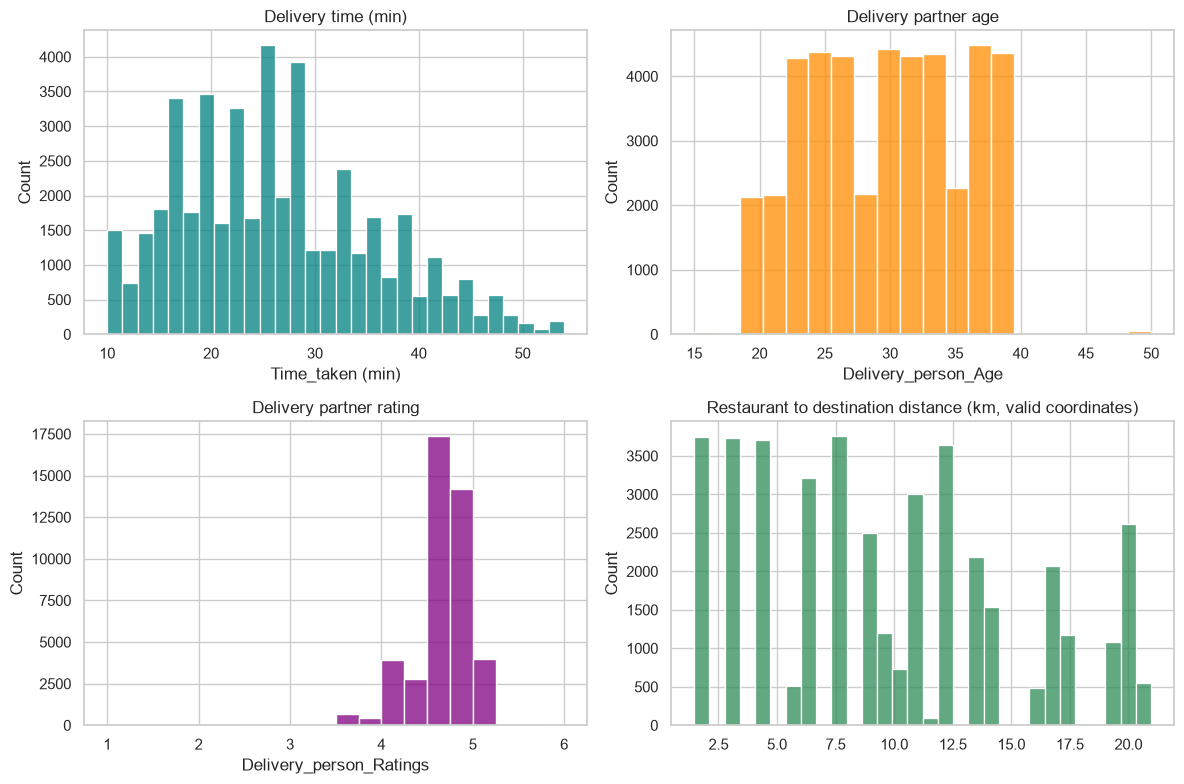

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(df[target_col], bins=30, ax=axes[0, 0], color="teal");  axes[0, 0].set_title("Delivery time (min)")
sns.histplot(age.dropna(), bins=20, ax=axes[0, 1], color="darkorange"); axes[0, 1].set_title("Delivery partner age")
sns.histplot(rating.dropna(), bins=20, ax=axes[1, 0], color="purple");  axes[1, 0].set_title("Delivery partner rating")
sns.histplot(dist_valid.dropna(), bins=30, ax=axes[1, 1], color="seagreen"); axes[1, 1].set_title("Restaurant to destination distance (km, valid coordinates)")
plt.tight_layout()
plt.show()

In [18]:
show_md(
    f"- **Age:** ranges from {age.min():.0f} to {age.max():.0f}. {age_low:,} rows are below {AGE_RANGE[0]} and {age_high:,} above {AGE_RANGE[1]}. These are unusual but not impossible, so they are flagged, not deleted.",
    f"- **Ratings:** range from {rating.min()} to {rating.max()}. **{rating_bad:,} rows fall outside the assumed 0 to {RATING_RANGE[1]} scale**, so those values cannot be valid ratings on that scale.",
    f"- **Delivery time:** ranges from {df[target_col].min()} to {df[target_col].max()} minutes. There are {int((df[target_col] < 0).sum())} negative values, so the minutes unit looks consistent.",
    f"- **Coordinates:** {int((~coords_ok).sum()):,} rows ({(~coords_ok).mean() * 100:.1f}%) have a restaurant or destination coordinate outside India's range. {rest_zero:,} restaurants sit exactly at latitude 0, longitude 0, which is in the Atlantic Ocean, so these look like placeholders for missing locations, not real places.",
    "- Distances computed from invalid coordinates (second table above) are unrealistic compared with those from valid coordinates, which confirms the invalid coordinates would corrupt any distance analysis.",
)

- **Age:** ranges from 15 to 50. 38 rows are below 18 and 0 above 65. These are unusual but not impossible, so they are flagged, not deleted.
- **Ratings:** range from 1.0 to 6.0. **53 rows fall outside the assumed 0 to 5 scale**, so those values cannot be valid ratings on that scale.
- **Delivery time:** ranges from 10 to 54 minutes. There are 0 negative values, so the minutes unit looks consistent.
- **Coordinates:** 4,071 rows (8.9%) have a restaurant or destination coordinate outside India's range. 3,640 restaurants sit exactly at latitude 0, longitude 0, which is in the Atlantic Ocean, so these look like placeholders for missing locations, not real places.
- Distances computed from invalid coordinates (second table above) are unrealistic compared with those from valid coordinates, which confirms the invalid coordinates would corrupt any distance analysis.

### 3.5 Dates, times and units

**What:** confirm the date format, check that dates and times parse, and examine the gap between order time and pickup time.
**Why:** a wrongly read date format (day-month vs month-day) silently produces wrong dates, and times given without dates can cross midnight.

In [19]:
date_raw = df["Order_Date"].astype("string").str.strip()
d_dayfirst = pd.to_datetime(date_raw, format="%d-%m-%Y", errors="coerce")
d_monthfirst = pd.to_datetime(date_raw, format="%m-%d-%Y", errors="coerce")
non_null_dates = int(date_raw.notna().sum())

print(f"Order_Date parsed as day-month-year  : {int(d_dayfirst.notna().sum())} of {non_null_dates} succeed")
print(f"Order_Date parsed as month-day-year  : {int(d_monthfirst.notna().sum())} of {non_null_dates} succeed")
print("Date range (day-month-year):", d_dayfirst.min().date(), "to", d_dayfirst.max().date())
print("Number of distinct dates   :", d_dayfirst.nunique())

t_ord = pd.to_datetime(df["Time_Orderd"].astype("string").str.strip(), format="%H:%M", errors="coerce")
t_pick = pd.to_datetime(df["Time_Order_picked"].astype("string").str.strip(), format="%H:%M", errors="coerce")
print()
print("Time_Orderd cells that are not a valid HH:MM time     :", int((df["Time_Orderd"].notna() & t_ord.isna()).sum()))
print("Time_Order_picked cells that are not a valid HH:MM time:", int((df["Time_Order_picked"].notna() & t_pick.isna()).sum()))

Order_Date parsed as day-month-year  : 45584 of 45584 succeed
Order_Date parsed as month-day-year  : 21001 of 45584 succeed
Date range (day-month-year): 2022-02-11 to 2022-04-06
Number of distinct dates   : 44

Time_Orderd cells that are not a valid HH:MM time     : 4068
Time_Order_picked cells that are not a valid HH:MM time: 5007


In [20]:
# Pickup gap in minutes. Times have no date, so a negative gap may simply mean the pickup was after midnight.
raw_gap = (t_pick - t_ord).dt.total_seconds() / 60
negative_gap = int((raw_gap < 0).sum())
wrapped_gap = raw_gap.where(raw_gap >= 0, raw_gap + 1440)

print("Rows with both times present:", int(raw_gap.notna().sum()))
print("Rows where pickup time is earlier than order time:", negative_gap)
print("\nPickup gap in minutes after allowing for midnight:")
print(wrapped_gap.describe().round(1).to_string())
print("\nAmong the negative-gap rows, gap after midnight adjustment:")
print(wrapped_gap[raw_gap < 0].describe().round(1).to_string() if negative_gap else "none")

Rows with both times present: 35407
Rows where pickup time is earlier than order time: 0

Pickup gap in minutes after allowing for midnight:
count    35407.0
mean         9.9
std          4.1
min          5.0
25%          5.0
50%         10.0
75%         15.0
max         15.0

Among the negative-gap rows, gap after midnight adjustment:
none


In [21]:
date_ok_day = int(d_dayfirst.notna().sum()) == non_null_dates
show_md(
    f"- **Date format:** {int(d_dayfirst.notna().sum()):,} of {non_null_dates:,} dates parse as day-month-year, versus {int(d_monthfirst.notna().sum()):,} as month-day-year. "
    + ("Day-month-year is therefore the correct reading." if date_ok_day else "Some dates still fail, so they need review."),
    f"- **Date range:** {d_dayfirst.min().date()} to {d_dayfirst.max().date()} ({d_dayfirst.nunique()} distinct days).",
    f"- **Times:** {negative_gap:,} rows have a pickup time earlier than the order time. After adding 24 hours these gaps become {wrapped_gap[raw_gap < 0].min() if negative_gap else 0:.0f} to {wrapped_gap[raw_gap < 0].max() if negative_gap else 0:.0f} minutes, which is consistent with orders that crossed midnight and not with data errors.",
    "- **Units:** delivery time is in minutes according to its column name, and the observed range is consistent with minutes. Times of day are stored as HH:MM text without dates, so any time arithmetic in later weeks must allow for midnight.",
)

- **Date format:** 45,584 of 45,584 dates parse as day-month-year, versus 21,001 as month-day-year. Day-month-year is therefore the correct reading.
- **Date range:** 2022-02-11 to 2022-04-06 (44 distinct days).
- **Times:** 0 rows have a pickup time earlier than the order time. After adding 24 hours these gaps become 0 to 0 minutes, which is consistent with orders that crossed midnight and not with data errors.
- **Units:** delivery time is in minutes according to its column name, and the observed range is consistent with minutes. Times of day are stored as HH:MM text without dates, so any time arithmetic in later weeks must allow for midnight.

## 4. Cleaning

All cleaning happens on `df_clean`, a copy of the raw data. Every step below is recorded in a **cleaning log** with the issue, affected rows, action taken and reason.

**Decision rules used**

| Situation | Decision | Reason |
|---|---|---|
| Extra spaces, capitalisation or spelling variants of the same label | Standardise | They are the same category written differently, so merging them loses no information |
| Hidden missing-value text such as `"NaN "` | Convert to a real missing value | It is a placeholder, not a real answer |
| Wrong data type (dates stored as text, whole numbers stored as decimals) | Convert | Needed for correct sorting, grouping and calculation |
| Exact duplicate rows | Remove, keeping the first | They add no information and would be double-counted |
| Same ID but different content | Retain and document | Cannot be resolved without the source system |
| Values impossible on the assumed scale (ratings above 5) | Set to missing | They cannot be valid, but no replacement value is invented |
| Unusual but possible values (age, delivery time outliers) | Retain and document | They may be genuine, so removal needs evidence |
| Invalid coordinates | Retain the row, add a flag column | Preserves the original values while letting later weeks exclude them from distance analysis |
| Missing values | Retain as missing, no imputation | Imputing would invent data, and the right method depends on the analysis in later weeks |

In [22]:
df_clean = df.copy()
cleaning_log = []

def log(issue, column, rows, action, reason):
    cleaning_log.append({"issue": issue, "affected_column": column, "affected_rows": int(rows),
                         "action_taken": action, "reason": reason})

rows_before = len(df_clean)
print("Working copy created. Rows:", rows_before)

Working copy created. Rows: 45584


### 4.1 Standardise column names

**What:** rename two columns. `Time_taken (min)` contains a space and brackets that make it awkward to use in code, and `Time_Orderd` is a misspelling of "Ordered".
**Why:** consistent names reduce errors in later weeks. The raw file keeps its original names.

In [23]:
renames = {"Time_taken (min)": "Time_taken_min", "Time_Orderd": "Time_Ordered"}
renames = {old: new for old, new in renames.items() if old in df_clean.columns}
df_clean = df_clean.rename(columns=renames)

for old, new in renames.items():
    log(f"Awkward or misspelled column name ('{old}')", old, len(df_clean),
        f"Renamed to '{new}'", "Names with spaces, brackets or typos are error-prone in code; values are unchanged")
print("Renamed:", renames)

Renamed: {'Time_taken (min)': 'Time_taken_min', 'Time_Orderd': 'Time_Ordered'}


### 4.2 Remove extra spaces and convert hidden placeholders to missing

**What:** strip leading/trailing spaces from text, then turn placeholder text such as `"NaN "` into real missing values.
**Why:** spaces split one category into several, and placeholders would otherwise be treated as real labels.

In [24]:
text_cols_clean = [c for c in df_clean.columns if not pd.api.types.is_numeric_dtype(df_clean[c])]

# Spaces
ws_total = 0
for c in text_cols_clean:
    s = df_clean[c]
    changed = int((s.notna() & (s != s.str.strip())).sum())
    if changed:
        df_clean[c] = s.str.strip()
        ws_total += changed
        log("Leading/trailing spaces in text", c, changed, "Stripped whitespace",
            "Same value written with different spacing would be counted as separate categories")
if ws_total == 0:
    log("Leading/trailing spaces in text", "all text columns", 0, "No action needed", "Checked: none found")

# Placeholders
ph_total = 0
for c in text_cols_clean:
    mask = placeholder_mask(df_clean[c])
    n = int(mask.sum())
    if n:
        df_clean.loc[mask, c] = np.nan
        ph_total += n
        log("Placeholder text standing for a missing value (e.g. 'NaN')", c, n, "Converted to a real missing value",
            "A placeholder is not a real answer; as a missing value it is counted and handled correctly")
if ph_total == 0:
    log("Placeholder text standing for a missing value", "all text columns", 0, "No action needed", "Checked: none found")

print("Cells with extra spaces stripped:", ws_total)
print("Placeholder cells converted to missing:", ph_total)

Cells with extra spaces stripped: 0
Placeholder cells converted to missing: 0


### 4.3 Standardise category labels

**What:** merge labels that differ only by capitalisation (keeping the most frequent form), then fix misspelled labels found in Section 3.3.
**Why:** each real category should appear under exactly one label.

In [25]:
# Capitalisation variants: map every variant to the most common spelling
case_total = 0
for c in [c for c in cat_cols if c in df_clean.columns]:
    s = df_clean[c]
    lowered = s.str.lower()
    canonical = s.groupby(lowered).agg(lambda x: x.value_counts().idxmax())
    mapped = lowered.map(canonical)
    changed = int((s.notna() & (s != mapped)).sum())
    if changed:
        df_clean[c] = mapped
        case_total += changed
        log("Same label in different capitalisation", c, changed, "Standardised to the most frequent form",
            "Merging variants of one label avoids splitting a category")
if case_total == 0:
    log("Same label in different capitalisation", "categorical columns", 0, "No action needed", "Checked: none found")

# Misspelled labels found by reading the label lists in Section 3.3.
# Edit this dictionary if you spot other misspellings in YOUR data.
LABEL_FIXES = {"City": {"Metropolitian": "Metropolitan"}}

spell_total = 0
for c, mapping in LABEL_FIXES.items():
    if c in df_clean.columns:
        n = int(df_clean[c].isin(mapping.keys()).sum())
        if n:
            df_clean[c] = df_clean[c].replace(mapping)
            spell_total += n
            log(f"Misspelled label {list(mapping.keys())}", c, n, f"Corrected to {list(mapping.values())}",
                "Clear spelling error applied to every occurrence; the meaning is unchanged")
if spell_total == 0:
    log("Misspelled category labels", "categorical columns", 0, "No action needed", "Checked: none found")

print("Capitalisation fixes:", case_total, "| spelling fixes:", spell_total)
for c in cat_cols:
    print(f"\n{c}:", df_clean[c].value_counts(dropna=False).to_dict())

Capitalisation fixes: 0 | spelling fixes: 34087

Weather_conditions: {'Fog': 7653, 'Stormy': 7584, 'Cloudy': 7533, 'Sandstorms': 7494, 'Windy': 7422, 'Sunny': 7282, nan: 616}

Road_traffic_density: {'Low': 15476, 'Jam': 14139, 'Medium': 10945, 'High': 4423, nan: 601}

Type_of_order: {'Snack': 11530, 'Meal': 11456, 'Drinks': 11321, 'Buffet': 11277}

Type_of_vehicle: {'motorcycle': 26429, 'scooter': 15273, 'electric_scooter': 3814, 'bicycle': 68}

Festival: {'No': 44460, 'Yes': 896, nan: 228}

City: {'Metropolitan': 34087, 'Urban': 10133, nan: 1200, 'Semi-Urban': 164}


### 4.4 Convert data types

**What:** convert `Order_Date` from text to a real date, validate the time columns, and store whole-number columns as integers (keeping missing values).
**Why:** dates as text cannot be sorted or filtered by period, and whole numbers stored as decimals (e.g. age 36.0) are misleading. Day-month-year was confirmed in Section 3.5.

In [26]:
# Order_Date: text -> date (day-month-year)
raw_dates = df_clean["Order_Date"]
parsed = pd.to_datetime(raw_dates, format="%d-%m-%Y", errors="coerce")
failed = int((raw_dates.notna() & parsed.isna()).sum())
df_clean["Order_Date"] = parsed
log("Order_Date stored as text", "Order_Date", int(parsed.notna().sum()), "Converted to a date type (day-month-year)",
    "Needed for date filtering and sorting; format verified in Section 3.5")
if failed:
    log("Order_Date values that do not parse", "Order_Date", failed, "Set to missing", "Cannot be read as a valid date")

# Time columns: keep as HH:MM text, but blank out anything that is not a valid time
for c in ["Time_Ordered", "Time_Order_picked"]:
    parsed_t = pd.to_datetime(df_clean[c], format="%H:%M", errors="coerce")
    bad = int((df_clean[c].notna() & parsed_t.isna()).sum())
    if bad:
        df_clean.loc[df_clean[c].notna() & parsed_t.isna(), c] = np.nan
        log("Invalid time format", c, bad, "Set to missing", "Not a valid HH:MM time")
    else:
        log("Invalid time format", c, 0, "No action needed", "Checked: all non-missing values are valid HH:MM times")

# Whole numbers stored as decimals because of missing values -> nullable integers
for c in ["Delivery_person_Age", "multiple_deliveries"]:
    if c in df_clean.columns:
        s = df_clean[c].dropna()
        if (s % 1 == 0).all():
            df_clean[c] = df_clean[c].astype("Int64")
            log("Whole numbers stored as decimals", c, len(s), "Converted to nullable integer type",
                "Values are whole numbers; the decimal type only existed to hold missing values")
        else:
            log("Non-integer values in a count/age column", c, int((s % 1 != 0).sum()), "Left unchanged", "Needs investigation")

print(df_clean.dtypes.to_string())

ID                                        str
Delivery_person_ID                        str
Delivery_person_Age                     Int64
Delivery_person_Ratings               float64
Restaurant_latitude                   float64
Restaurant_longitude                  float64
Delivery_location_latitude            float64
Delivery_location_longitude           float64
Order_Date                     datetime64[us]
Time_Ordered                              str
Time_Order_picked                         str
Weather_conditions                        str
Road_traffic_density                      str
Vehicle_condition                       int64
Type_of_order                             str
Type_of_vehicle                           str
multiple_deliveries                     Int64
Festival                                  str
City                                      str
Time_taken_min                          int64


### 4.5 Invalid and unusual values

**What:** treat impossible ratings, flag implausible ages and coordinates, and note outliers.
**Why:** these problems were measured in Section 3.4. Impossible values are set to missing, and unusual-but-possible values are kept with an explanation.

In [27]:
# Ratings outside the assumed 0-5 scale: impossible values -> missing (no replacement invented)
r = df_clean["Delivery_person_Ratings"]
bad_rating = (r < RATING_RANGE[0]) | (r > RATING_RANGE[1])
n_bad_rating = int(bad_rating.sum())
if n_bad_rating:
    df_clean.loc[bad_rating, "Delivery_person_Ratings"] = np.nan
    log("Ratings outside the assumed 0-5 scale", "Delivery_person_Ratings", n_bad_rating, "Set to missing",
        "Cannot be valid on a 5-point scale (assumption: scale is 0-5; scale is not documented). The raw file keeps the original values")
else:
    log("Ratings outside the assumed 0-5 scale", "Delivery_person_Ratings", 0, "No action needed", "Checked: none found")

# Age: retain, document
a = df_clean["Delivery_person_Age"]
n_age = int(((a < AGE_RANGE[0]) | (a > AGE_RANGE[1])).sum())
log(f"Delivery partner age outside the assumed plausible range {AGE_RANGE}", "Delivery_person_Age", n_age,
    "Retained and documented" if n_age else "No action needed",
    "Unusual but possible, and the data cannot show whether they are errors; removing them without evidence would be unjustified" if n_age else "Checked: none found")

# Coordinates: keep the original values, add a flag column
rest_ok_c = valid_pair(df_clean["Restaurant_latitude"], df_clean["Restaurant_longitude"])
dest_ok_c = valid_pair(df_clean["Delivery_location_latitude"], df_clean["Delivery_location_longitude"])
df_clean["has_valid_coordinates"] = (rest_ok_c & dest_ok_c)
n_bad_coord = int((~df_clean["has_valid_coordinates"]).sum())
log("Coordinates outside India's range (including 0,0 and negative values)",
    "Restaurant_latitude, Restaurant_longitude, Delivery_location_latitude, Delivery_location_longitude", n_bad_coord,
    "Retained; added boolean column 'has_valid_coordinates' (False = invalid)",
    "Rows still hold valid delivery times and other fields, and correcting coordinates (e.g. flipping signs) would be guesswork. Later distance analysis should filter on this flag")

# Outliers: retain, document
for c in [c for c in ["Time_taken_min", "Delivery_person_Age", "Delivery_person_Ratings"] if c in df_clean.columns]:
    n_out = iqr_outliers(df_clean[c].astype("float64"))
    log("Statistical outliers (outside 1.5 x IQR)", c, n_out, "Retained and documented" if n_out else "No action needed",
        "Extreme values can be genuine (e.g. a slow delivery in bad weather); removal needs a documented reason" if n_out else "Checked: none found")

print("Ratings set to missing:", n_bad_rating)
print("Rows flagged with invalid coordinates:", n_bad_coord)

Ratings set to missing: 53
Rows flagged with invalid coordinates: 4071


### 4.6 Duplicates

**What:** inspect duplicate rows, then remove only exact copies.
**Why:** exact copies add no information. Rows sharing an ID but differing in content are kept, because the data cannot show which version is correct.

In [28]:
exact_dups = df_clean.duplicated(keep="first")
n_exact = int(exact_dups.sum())

if n_exact:
    print("Examples of exact duplicate rows:")
    display(df_clean[df_clean.duplicated(keep=False)].sort_values("ID").head(6))

df_clean = df_clean[~exact_dups].reset_index(drop=True)
log("Exact duplicate rows", "all columns", n_exact, "Removed (first occurrence kept)" if n_exact else "No action needed",
    "Identical in every column, so they add no information and would be double-counted" if n_exact else "Checked: none found")

n_same_id = int(df_clean["ID"].duplicated(keep=False).sum())
log("Same ID with different content", "ID", n_same_id, "Retained and documented" if n_same_id else "No action needed",
    "The rows differ, and without the source system there is no evidence which version is correct" if n_same_id else "Checked: none found")

print("Exact duplicates removed:", n_exact)
print("Rows still sharing an ID with another row:", n_same_id)
print("Rows now:", len(df_clean))

Exact duplicates removed: 0
Rows still sharing an ID with another row: 0
Rows now: 45584


### 4.7 Missing values

**What:** record the remaining missing values per column.
**Why:** missing values are **not imputed in Week 1**. Filling them would invent data, and the best method (or whether to exclude rows) depends on the analysis in later weeks. Any later imputation must be explained and its limitations stated.

In [29]:
missing_after = df_clean.isna().sum()
for c, n in missing_after[missing_after > 0].sort_values(ascending=False).items():
    log("Missing values", c, n, "Retained as missing (not imputed)",
        "Imputing would invent values; handling will be decided per analysis in later weeks")
if missing_after.sum() == 0:
    log("Missing values", "all columns", 0, "No action needed", "Checked: none remaining")

display(pd.DataFrame({"Missing after cleaning": missing_after[missing_after > 0],
                      "Missing %": (missing_after[missing_after > 0] / len(df_clean) * 100).round(2)}))

,Missing after cleaning,Missing %
Delivery_person_Age,1854,4.07
Delivery_person_Ratings,1961,4.30
Time_Ordered,5799,12.72
Time_Order_picked,5007,10.98
Weather_conditions,616,1.35
Road_traffic_density,601,1.32
multiple_deliveries,993,2.18
Festival,228,0.50
City,1200,2.63


## 5. Verify and Export

**What:** compare original and cleaned data, confirm the raw data is unchanged, export the cleaned file, reopen it, and save the cleaning log.
**Why:** a reviewer must be able to trust that the exported file is exactly what was cleaned here.

In [30]:
rows_raw, rows_clean = len(df), len(df_clean)
n_exact_removed = n_exact

comparison = pd.DataFrame({
    "Metric": ["Rows", "Columns", "Missing cells", "Exact duplicate rows"],
    "Original": [rows_raw, df.shape[1], int(df.isna().sum().sum()), int(df.duplicated().sum())],
    "Cleaned": [rows_clean, df_clean.shape[1], int(df_clean.isna().sum().sum()), int(df_clean.duplicated().sum())],
})
show_md("**Before and after**", "", md_table(comparison))

raw_unchanged = df.equals(df_snapshot)
print("Raw DataFrame identical to the snapshot taken at load time:", raw_unchanged)
assert rows_raw - n_exact_removed == rows_clean, "Row counts do not reconcile"

show_md(
    f"- **Rows:** {rows_raw:,} before, {rows_clean:,} after. The difference of **{rows_raw - rows_clean:,} rows** is entirely the exact duplicates removed in Section 4.6. No other rows were deleted.",
    f"- **Columns:** {df.shape[1]} before, {df_clean.shape[1]} after. The extra column is `has_valid_coordinates`.",
    f"- **Missing cells:** {int(df.isna().sum().sum()):,} before and {int(df_clean.isna().sum().sum()):,} after. The change comes from converting hidden placeholders and impossible ratings to real missing values, so more cells are now correctly counted as missing, not fewer.",
    f"- **Raw data unchanged:** {raw_unchanged}.",
)

**Before and after**

| Metric | Original | Cleaned |
| --- | --- | --- |
| Rows | 45584 | 45584 |
| Columns | 20 | 21 |
| Missing cells | 9131 | 18259 |
| Exact duplicate rows | 0 | 0 |

Raw DataFrame identical to the snapshot taken at load time: True


- **Rows:** 45,584 before, 45,584 after. The difference of **0 rows** is entirely the exact duplicates removed in Section 4.6. No other rows were deleted.
- **Columns:** 20 before, 21 after. The extra column is `has_valid_coordinates`.
- **Missing cells:** 9,131 before and 18,259 after. The change comes from converting hidden placeholders and impossible ratings to real missing values, so more cells are now correctly counted as missing, not fewer.
- **Raw data unchanged:** True.

In [31]:
PROCESSED_DIR = os.path.join(PROJECT_ROOT, "data", "processed")
DOCS_DIR = os.path.join(PROJECT_ROOT, "docs")
os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(DOCS_DIR, exist_ok=True)

OUT_PATH = os.path.join(PROCESSED_DIR, "cleaned_food_delivery.csv")
LOG_PATH = os.path.join(DOCS_DIR, "cleaning_log.csv")

df_clean.to_csv(OUT_PATH, index=False)

log_df = pd.DataFrame(cleaning_log, columns=["issue", "affected_column", "affected_rows", "action_taken", "reason"])
log_df.to_csv(LOG_PATH, index=False)

print("Cleaned data saved to:", OUT_PATH)
print("Cleaning log saved to:", LOG_PATH)

Cleaned data saved to: C:\Users\HP\Documents\food-delivery-data-analysis\data\processed\cleaned_food_delivery.csv
Cleaning log saved to: C:\Users\HP\Documents\food-delivery-data-analysis\docs\cleaning_log.csv


In [32]:
# Reopen the exported file and verify it
reloaded = pd.read_csv(OUT_PATH)

checks = {
    "Same number of rows": reloaded.shape[0] == df_clean.shape[0],
    "Same number of columns": reloaded.shape[1] == df_clean.shape[1],
    "Same column names": list(reloaded.columns) == list(df_clean.columns),
    "Missing values per column unchanged": (reloaded.isna().sum().values == df_clean.isna().sum().values).all(),
    "Order_Date reads back as valid dates": pd.to_datetime(reloaded["Order_Date"], errors="coerce").notna().sum() == df_clean["Order_Date"].notna().sum(),
}
for name, ok in checks.items():
    print(("PASS  " if ok else "FAIL  ") + name)
assert all(checks.values()), "Export verification failed"

print("\nReloaded shape:", reloaded.shape)
display(reloaded.head())

PASS  Same number of rows
PASS  Same number of columns
PASS  Same column names
PASS  Missing values per column unchanged
PASS  Order_Date reads back as valid dates

Reloaded shape: (45584, 21)


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Ordered,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken_min,has_valid_coordinates
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,2022-02-12,21:55,22:10,Fog,Jam,2,Snack,motorcycle,3.0,No,Metropolitan,46,True
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,2022-02-13,14:55,15:05,Stormy,High,1,Meal,motorcycle,1.0,No,Metropolitan,23,True
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,2022-03-04,17:30,17:40,Sandstorms,Medium,1,Drinks,scooter,1.0,No,Metropolitan,21,True
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,2022-02-13,09:20,09:30,Sandstorms,Low,0,Buffet,motorcycle,0.0,No,Metropolitan,20,True
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,2022-02-14,19:50,20:05,Fog,Jam,1,Snack,scooter,1.0,No,Metropolitan,41,True


In [33]:
display(log_df)

,issue,affected_column,affected_rows,action_taken,reason
0,Awkward or misspelled column name ('Time_taken...,Time_taken (min),45584,Renamed to 'Time_taken_min',"Names with spaces, brackets or typos are error..."
1,Awkward or misspelled column name ('Time_Orderd'),Time_Orderd,45584,Renamed to 'Time_Ordered',"Names with spaces, brackets or typos are error..."
2,Leading/trailing spaces in text,all text columns,0,No action needed,Checked: none found
3,Placeholder text standing for a missing value,all text columns,0,No action needed,Checked: none found
4,Same label in different capitalisation,categorical columns,0,No action needed,Checked: none found
5,Misspelled label ['Metropolitian'],City,34087,Corrected to ['Metropolitan'],Clear spelling error applied to every occurren...
6,Order_Date stored as text,Order_Date,45584,Converted to a date type (day-month-year),Needed for date filtering and sorting; format ...
7,Invalid time format,Time_Ordered,4068,Set to missing,Not a valid HH:MM time
8,Invalid time format,Time_Order_picked,5007,Set to missing,Not a valid HH:MM time
9,Whole numbers stored as decimals,Delivery_person_Age,43730,Converted to nullable integer type,Values are whole numbers; the decimal type onl...


### 5.1 Summary for the README

In [34]:
fixed_rows = log_df[log_df["affected_rows"] > 0]
show_md(
    "**Week 1 summary (calculated from this run)**",
    "",
    f"- Raw dataset: {rows_raw:,} rows x {df.shape[1]} columns. Cleaned dataset: {rows_clean:,} rows x {df_clean.shape[1]} columns.",
    f"- Exact duplicate rows removed: {n_exact_removed:,}.",
    f"- Hidden text placeholders converted to missing: {ph_total:,}.",
    f"- Ratings outside the assumed 0-5 scale set to missing: {n_bad_rating:,}.",
    f"- Rows flagged with invalid coordinates (kept): {n_bad_coord:,}.",
    f"- Cleaning-log entries with affected rows: {len(fixed_rows)} of {len(log_df)}.",
    f"- Most missing column after cleaning: {missing_after.idxmax()} ({missing_after.max():,} missing, {missing_after.max() / len(df_clean) * 100:.1f}%).",
)

**Week 1 summary (calculated from this run)**

- Raw dataset: 45,584 rows x 20 columns. Cleaned dataset: 45,584 rows x 21 columns.
- Exact duplicate rows removed: 0.
- Hidden text placeholders converted to missing: 0.
- Ratings outside the assumed 0-5 scale set to missing: 53.
- Rows flagged with invalid coordinates (kept): 4,071.
- Cleaning-log entries with affected rows: 22 of 28.
- Most missing column after cleaning: Time_Ordered (5,799 missing, 12.7%).

## 6. Assumptions and Limitations

- **No data dictionary was provided.** Column meanings are inferred from names. The rating scale (assumed 0 to 5), the plausible age range (assumed 18 to 65) and the India coordinate bounds are assumptions, and each affects a cleaning decision logged above.
- **Missing values were not imputed.** Rows with missing values remain, so later analysis must choose a handling method per question and explain its limits.
- **Invalid coordinates were flagged, not corrected.** Any later distance analysis should filter on `has_valid_coordinates`.
- **Same-ID rows with different content were kept**, because the data cannot show which version is correct.
- **Outliers were retained.** Their influence should be checked, for example by comparing results with and without them, before drawing conclusions.
- **Time columns hold times of day without dates**, so time differences must allow for midnight.
- **Association is not causation.** Patterns found in later weeks describe relationships in this dataset, not proven causes.
- Add your own comments here after reviewing the results above. The written results in this notebook are generated from the data, but your interpretation and reasoning should also appear in your own words.